# Implementing a Genetic Algorithm

## Objective
Develop a basic real-coded genetic algorithm in Python
to minimise the objective function:

$$f(x) = (x - 5)^2$$

The search interval is $0 \leq x \leq 10$.

The algorithm will use tournament selection, arithmetic
crossover, Gaussian mutation and elitism.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
rng = np.random.default_rng(42)

## 1. Problem definition and algorithm parameters

The algorithm searches for the value of $x$ that minimises
the objective function.

The candidate solutions must remain within the interval
[0, 10].

In [3]:
# Search boundaries
lower_bound = 0.0
upper_bound = 10.0

# Genetic algorithm settings
population_size = 20
number_generations = 50

# Evolutionary operation settings
crossover_probability = 0.9
mutation_probability = 0.2
mutation_scale = 0.5

# Selection and elitism settings
tournament_size = 3
elitism_count = 1

## 2. Objective-function definition

The objective function measures the quality of each
candidate solution.

Our goal is to minimise:

$$f(x) = (x - 5)^2$$

A smaller objective value represents a better candidate.

In [4]:
def objective(x):
    return (x - 5)**2

In [5]:
test_values = np.array([1, 3, 5, 7, 9])

test_results = objective(test_values)

print(test_results)

[16  4  0  4 16]


## 3. Population initialisation

The initial population consists of randomly generated
candidate solutions within the search interval.

Each candidate represents one possible value of x.

In [6]:
population = rng.uniform(
    lower_bound,
    upper_bound,
    size=population_size
)

print(population)

[7.73956049 4.3887844  8.5859792  6.97368029 0.94177348 9.75622352
 7.61139702 7.86064305 1.28113633 4.50385938 3.70798024 9.26764989
 6.4386512  8.22761613 4.43414199 2.27238722 5.54584787 0.63817256
 8.27631172 6.31664399]


## 4. Population evaluation

Evaluate every candidate using the objective function.

The candidate with the smallest objective value
is currently the best solution.

In [7]:
objective_values = objective(population)

for i, (candidate, value) in enumerate(
    zip(population, objective_values)
):
    print(
        f"Individual {i+1}: "
        f"x = {candidate:.4f}, "
        f"objective = {value:.4f}"
    )

Individual 1: x = 7.7396, objective = 7.5052
Individual 2: x = 4.3888, objective = 0.3736
Individual 3: x = 8.5860, objective = 12.8592
Individual 4: x = 6.9737, objective = 3.8954
Individual 5: x = 0.9418, objective = 16.4692
Individual 6: x = 9.7562, objective = 22.6217
Individual 7: x = 7.6114, objective = 6.8194
Individual 8: x = 7.8606, objective = 8.1833
Individual 9: x = 1.2811, objective = 13.8299
Individual 10: x = 4.5039, objective = 0.2462
Individual 11: x = 3.7080, objective = 1.6693
Individual 12: x = 9.2676, objective = 18.2128
Individual 13: x = 6.4387, objective = 2.0697
Individual 14: x = 8.2276, objective = 10.4175
Individual 15: x = 4.4341, objective = 0.3202
Individual 16: x = 2.2724, objective = 7.4399
Individual 17: x = 5.5458, objective = 0.2979
Individual 18: x = 0.6382, objective = 19.0255
Individual 19: x = 8.2763, objective = 10.7342
Individual 20: x = 6.3166, objective = 1.7336


In [8]:
best_index = np.argmin(objective_values)

best_candidate = population[best_index]
best_value = objective_values[best_index]

print("Best candidate:", best_candidate)
print("Best objective value:", best_value)

Best candidate: 4.503859378955672
Best objective value: 0.24615551585025192


## 5. Tournament selection

Tournament selection randomly chooses a specified
number of candidates and selects the best among them.

We use tournament selection to choose parents for reproduction.

In [9]:
def tournament_selection(
    population,
    objective_values,
    tournament_size
):
    # Randomly select competitors
    competitor_indices = rng.choice(
        len(population),
        size=tournament_size,
        replace=False
    )

    # Identify the competitor with the smallest objective
    winner_index = competitor_indices[
        np.argmin(objective_values[competitor_indices])
    ]

    # Return the winning candidate
    return population[winner_index]

In [10]:
parent = tournament_selection(
    population,
    objective_values,
    tournament_size
)

print("Selected parent:", parent)
print("Parent objective:", objective(parent))

Selected parent: 4.4341419882733115
Parent objective: 0.32019528943528114


## 6. Arithmetic crossover

Crossover combines information from two parent solutions
to produce an offspring.

We will use arithmetic crossover for our real-valued
candidate representation.

In [11]:
def arithmetic_crossover(parent1, parent2):

    alpha = rng.random()

    child = (
        alpha * parent1
        + (1 - alpha) * parent2
    )

    return child

In [12]:
child = arithmetic_crossover(3, 7)

print("Parent 1:", 3)
print("Parent 2:", 7)
print("Offspring:", child)

Parent 1: 3
Parent 2: 7
Offspring: 3.4275155147112093


## 7. Gaussian mutation

Mutation introduces random variation into an offspring.

We will use Gaussian mutation, which adds a random
perturbation drawn from a normal distribution.

In [13]:
def mutate(
    child,
    mutation_probability,
    mutation_scale
):

    if rng.random() < mutation_probability:

        child += rng.normal(
            loc=0.0,
            scale=mutation_scale
        )

    # Keep the candidate within the search boundaries
    child = np.clip(
        child,
        lower_bound,
        upper_bound
    )

    return child

In [14]:
test_child = 6.0

mutated_child = mutate(
    test_child,
    mutation_probability,
    mutation_scale
)

print("Original child:", test_child)
print("After mutation:", mutated_child)

Original child: 6.0
After mutation: 6.0


## 8. Genetic algorithm implementation

The algorithm will repeat the following process:

1. Evaluate the current population.
2. Identify the best candidate.
3. Preserve the best candidate through elitism.
4. Select parents using tournament selection.
5. Apply crossover with the specified probability.
6. Apply mutation to the offspring.
7. Form the next generation.
8. Repeat until the maximum number of generations is reached.

In [15]:
# Store results from each generation
history = {
    "best_objective": [],
    "mean_objective": [],
    "best_candidate": []
}


# Evolutionary process
for generation in range(number_generations + 1):

    # Evaluate the current population
    objective_values = objective(population)

    # Identify the best candidate
    best_index = np.argmin(objective_values)

    best_candidate = population[best_index]
    best_value = objective_values[best_index]

    # Record performance
    history["best_objective"].append(best_value)
    history["mean_objective"].append(
        np.mean(objective_values)
    )
    history["best_candidate"].append(best_candidate)

    # Stop after recording the final generation
    if generation == number_generations:
        break

    # Begin the next generation
    next_population = []

    # Preserve the best candidate (elitism)
    next_population.append(best_candidate)

    # Generate the remaining offspring
    while len(next_population) < population_size:

        # Select two parents
        parent1 = tournament_selection(
            population,
            objective_values,
            tournament_size
        )

        parent2 = tournament_selection(
            population,
            objective_values,
            tournament_size
        )

        # Apply crossover with a probability
        if rng.random() < crossover_probability:

            child = arithmetic_crossover(
                parent1,
                parent2
            )

        else:
            child = parent1

        # Apply mutation
        child = mutate(
            child,
            mutation_probability,
            mutation_scale
        )

        # Add offspring to the next generation
        next_population.append(child)

    # Replace the current population
    population = np.array(next_population)

## 9. Final result

Identify the best solution found across all recorded
generations and compare it with the known mathematical
optimum.

In [16]:
best_generation_index = np.argmin(
    history["best_objective"]
)

estimated_x = history["best_candidate"][
    best_generation_index
]

estimated_objective = history["best_objective"][
    best_generation_index
]

print("Best estimated x:", estimated_x)
print("Best objective value:", estimated_objective)

print("\nKnown mathematical optimum:")
print("x =", 5.0)
print("Objective value =", objective(5.0))

Best estimated x: 5.0
Best objective value: 0.0

Known mathematical optimum:
x = 5.0
Objective value = 0.0


## 10. Convergence analysis

Examine how the best and average objective values
change over successive generations.

A decreasing best objective value indicates that
the algorithm is finding progressively better solutions.

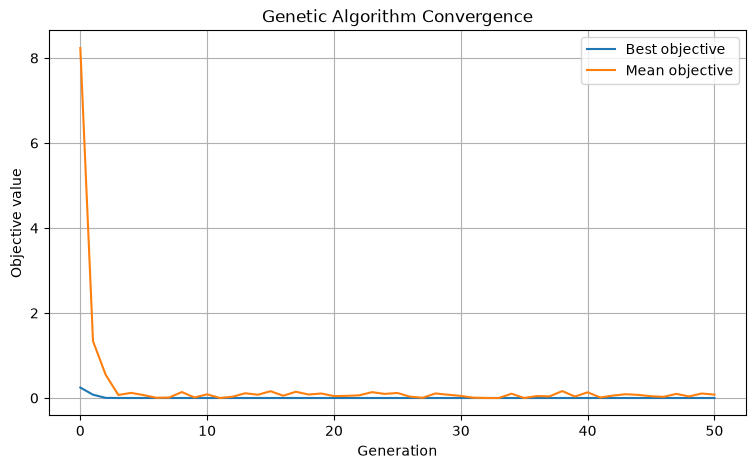

In [17]:
plt.figure(figsize=(9, 5))

plt.plot(
    history["best_objective"],
    label="Best objective"
)

plt.plot(
    history["mean_objective"],
    label="Mean objective"
)

plt.xlabel("Generation")
plt.ylabel("Objective value")

plt.title("Genetic Algorithm Convergence")

plt.legend()
plt.grid(True)

plt.show()